# Phase 2 : Exploration des données (EDA) — Bike Sharing (`hour.csv`)

**Objectif du projet :** prévoir `cnt` (nombre total de locations de vélos par heure).

Plan de ce notebook :
1. Types, valeurs manquantes, doublons, cohérence des dates
2. Continuité temporelle
3. Distribution de `cnt`
4. Demande selon `hr`, `weekday`, `mnth`, `season`, `yr`, `holiday`
5. Jours ouvrés vs week-end
6. Impact de la météo
7. Corrélations et multicolinéarité
8. `casual` vs `registered`
9. Croissance 2011 → 2012

> `casual` et `registered` sont utilisées ici **uniquement pour comprendre les données** (fuite de données : `cnt = casual + registered`). Elles ne seront pas utilisées comme features.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)

DATA_PATH = "../hour.csv"   

df = pd.read_csv(DATA_PATH, parse_dates=["dteday"])
print("Dimensions :", df.shape)
df.head()

Dimensions : (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## 1. Types, valeurs manquantes, doublons, cohérence des dates

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[us]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-null  int64

In [9]:
print("Valeurs manquantes (total) :", int(df.isna().sum().sum()))
print("Lignes entièrement dupliquées :", int(df.duplicated().sum()))
print("Doublons sur (dteday, hr) :", int(df.duplicated(["dteday", "hr"]).sum()))
print("instant unique et croissant :", df["instant"].is_unique and df["instant"].is_monotonic_increasing)
print("Période couverte :", df["dteday"].min().date(), "->", df["dteday"].max().date())
df.describe().T

Valeurs manquantes (total) : 0
Lignes entièrement dupliquées : 0
Doublons sur (dteday, hr) : 0
instant unique et croissant : True
Période couverte : 2011-01-01 -> 2012-12-31


,count,mean,min,25%,50%,75%,max,std
instant,17379.0,8690.0,1.0,4345.5,8690.0,13034.5,17379.0,5017.0295
dteday,17379,2012-01-02 04:08:34.552045,2011-01-01 00:00:00,2011-07-04 00:00:00,2012-01-02 00:00:00,2012-07-02 00:00:00,2012-12-31 00:00:00,NaN
season,17379.0,2.50164,1.0,2.0,3.0,3.0,4.0,1.106918
yr,17379.0,0.502561,0.0,0.0,1.0,1.0,1.0,0.500008
mnth,17379.0,6.537775,1.0,4.0,7.0,10.0,12.0,3.438776
hr,17379.0,11.546752,0.0,6.0,12.0,18.0,23.0,6.914405
holiday,17379.0,0.02877,0.0,0.0,0.0,0.0,1.0,0.167165
weekday,17379.0,3.003683,0.0,1.0,3.0,5.0,6.0,2.005771
workingday,17379.0,0.682721,0.0,0.0,1.0,1.0,1.0,0.465431
weathersit,17379.0,1.425283,1.0,1.0,1.0,2.0,4.0,0.639357


In [10]:
# Chaque valeur = nombre de lignes incohérentes (0 = tout est cohérent)
# Dans ce dataset : weekday 0 = dimanche, pandas : lundi = 0 -> on convertit
weekday_calc = (df["dteday"].dt.dayofweek + 1) % 7
workingday_calc = ((~df["weekday"].isin([0, 6])) & (df["holiday"] == 0)).astype(int)

checks = {
    "yr incohérent avec dteday":               int((df["dteday"].dt.year - 2011 != df["yr"]).sum()),
    "mnth incohérent avec dteday":             int((df["dteday"].dt.month != df["mnth"]).sum()),
    "weekday incohérent avec dteday":          int((weekday_calc != df["weekday"]).sum()),
    "workingday incohérent (weekday/holiday)": int((workingday_calc != df["workingday"]).sum()),
    "cnt != casual + registered":              int((df["cnt"] != df["casual"] + df["registered"]).sum()),
    "hr hors [0, 23]":                         int((~df["hr"].between(0, 23)).sum()),
    "dteday non trié":                         int((df["dteday"].diff().dropna() < pd.Timedelta(0)).sum()),
    "variables normalisées hors [0, 1]":       int((~df[["temp", "atemp", "hum", "windspeed"]].apply(lambda s: s.between(0, 1)).all(axis=1)).sum()),
}
pd.Series(checks, name="nb de lignes incohérentes").to_frame()

/tmp/ipykernel_31550/2851649598.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  weekday_calc = (df["dteday"].dt.dayofweek + 1) % 7


,nb de lignes incohérentes
yr incohérent avec dteday,0
mnth incohérent avec dteday,0
weekday incohérent avec dteday,0
workingday incohérent (weekday/holiday),0
cnt != casual + registered,0
"hr hors [0, 23]",0
dteday non trié,0
"variables normalisées hors [0, 1]",0


## 2. Continuité temporelle

On reconstruit un timestamp complet (`dteday` + `hr`) et on compare avec la grille horaire théorique.
Une ligne n'existe que s'il y a eu au moins une location : les heures sans location (surtout la nuit) sont absentes.

Lignes présentes        : 17,379
Heures théoriques       : 17,544
Heures absentes         : 165 (0.9%)


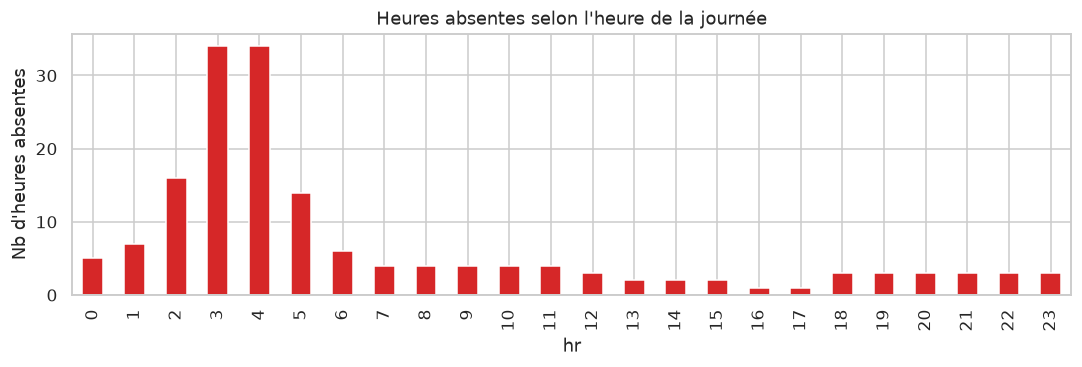

In [11]:
df["ts"] = df["dteday"] + pd.to_timedelta(df["hr"], unit="h")

full_range = pd.date_range(df["ts"].min(), df["ts"].max(), freq="h")
missing_ts = full_range.difference(pd.DatetimeIndex(df["ts"]))

print(f"Lignes présentes        : {len(df):,}")
print(f"Heures théoriques       : {len(full_range):,}")
print(f"Heures absentes         : {len(missing_ts):,} ({len(missing_ts) / len(full_range):.1%})")

missing_by_hr = pd.Series(missing_ts.hour).value_counts().reindex(range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(10, 3.5))
missing_by_hr.plot(kind="bar", ax=ax, color="tab:red")
ax.set(title="Heures absentes selon l'heure de la journée", xlabel="hr", ylabel="Nb d'heures absentes")
plt.tight_layout(); plt.show()

In [28]:
# Jours entièrement absents
all_days = pd.date_range(df["dteday"].min(), df["dteday"].max(), freq="D")
missing_days = all_days.difference(pd.DatetimeIndex(df["dteday"].unique()))
print("Jours entièrement absents :", len(missing_days))
if len(missing_days):
    print(list(missing_days.date))

# Écarts entre deux lignes consécutives
gaps = df["ts"].diff().dropna()
print("\nRépartition des écarts entre lignes consécutives :")
print(gaps.value_counts().head(8))

print("\nPlus longs trous :")
longest = gaps.sort_values(ascending=False).head(5)
pd.DataFrame({"ecart": longest, "fin_du_trou": df.loc[longest.index, "ts"]})

Jours entièrement absents : 0

Répartition des écarts entre lignes consécutives :
ts
0 days 01:00:00    17303
0 days 02:00:00       64
0 days 03:00:00        6
0 days 13:00:00        1
0 days 23:00:00        1
0 days 07:00:00        1
0 days 14:00:00        1
1 days 13:00:00        1
Name: count, dtype: int64

Plus longs trous :


,ecart,fin_du_trou
15884,1 days 13:00:00,2012-10-30 13:00:00
587,0 days 23:00:00,2011-01-27 16:00:00
5636,0 days 14:00:00,2011-08-28 07:00:00
396,0 days 13:00:00,2011-01-18 12:00:00
1181,0 days 07:00:00,2011-02-22 06:00:00


## 3. Distribution de `cnt`

count    17379.000000
mean       189.463088
std        181.387599
min          1.000000
25%         40.000000
50%        142.000000
75%        281.000000
max        977.000000
Name: cnt, dtype: float64

Asymétrie (skew)  cnt        : 1.28
Asymétrie (skew)  log1p(cnt) : -0.82

Seuil outlier (Q3 + 1.5 IQR) : 642  ->  505 lignes (2.9%)


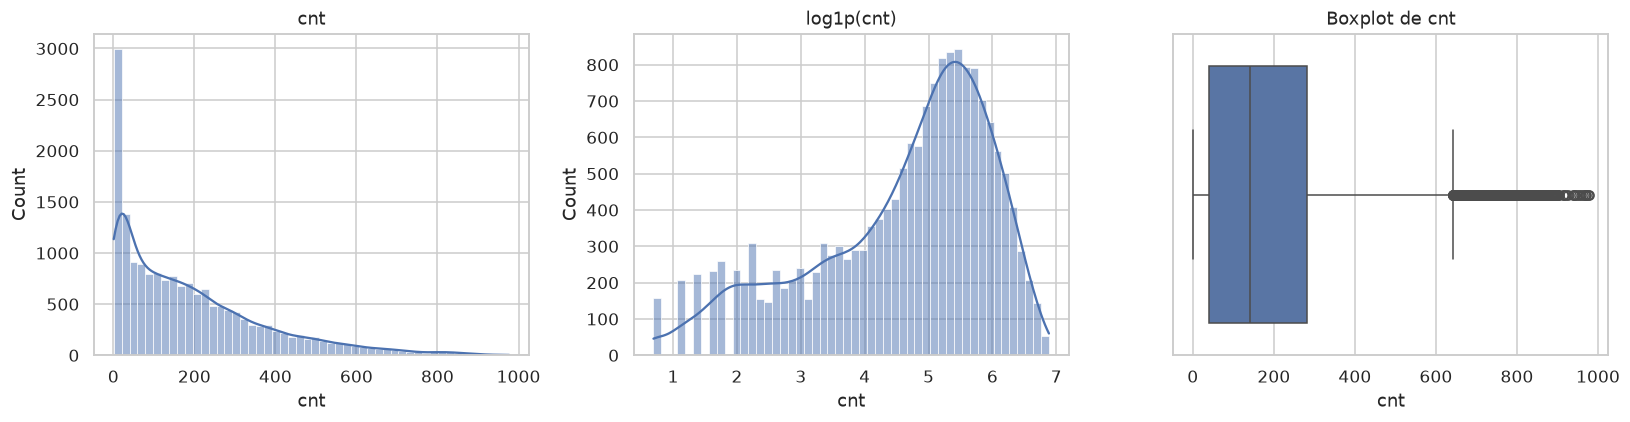

In [44]:
print(df["cnt"].describe())
print(f"\nAsymétrie (skew)  cnt        : {df['cnt'].skew():.2f}")
print(f"Asymétrie (skew)  log1p(cnt) : {np.log1p(df['cnt']).skew():.2f}")

q1, q3 = df["cnt"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
n_out = int((df["cnt"] > upper).sum())
print(f"\nSeuil outlier (Q3 + 1.5 IQR) : {upper:.0f}  ->  {n_out} lignes ({n_out / len(df):.1%})")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["cnt"], bins=50, kde=True, ax=axes[0]);            axes[0].set_title("cnt")
sns.histplot(np.log1p(df["cnt"]), bins=50, kde=True, ax=axes[1]);  axes[1].set_title("log1p(cnt)")
sns.boxplot(x=df["cnt"], ax=axes[2]);                              axes[2].set_title("Boxplot de cnt")
plt.tight_layout(); plt.show()

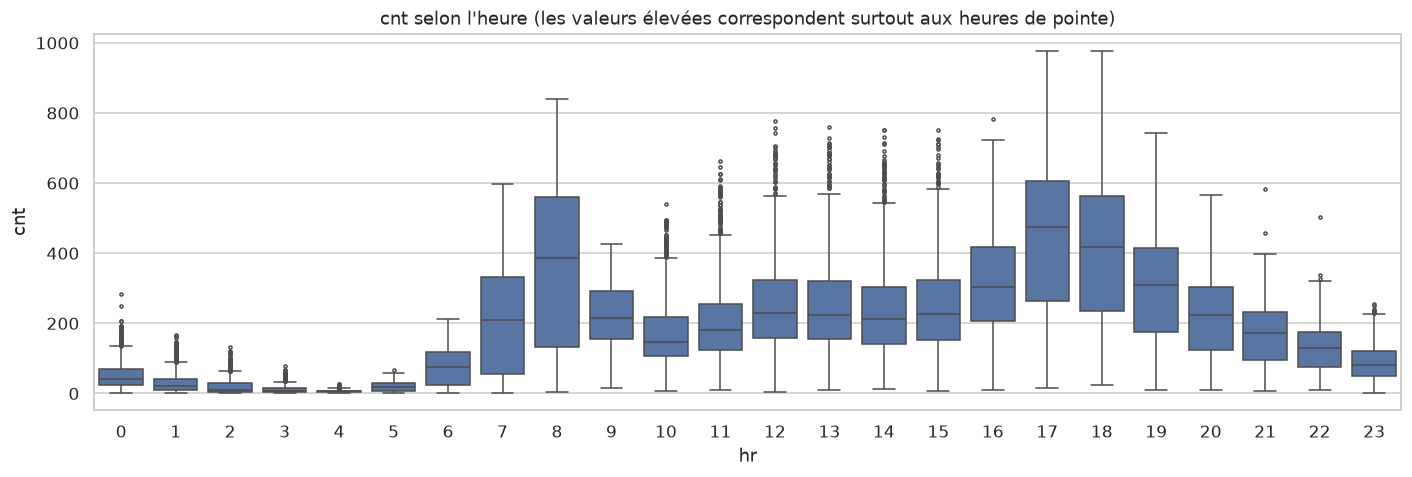

In [45]:
# Les "outliers" globaux sont-ils en fait normaux à certaines heures ? -> boxplot par heure
fig, ax = plt.subplots(figsize=(13, 4.5))
sns.boxplot(data=df, x="hr", y="cnt", ax=ax, fliersize=2)
ax.set_title("cnt selon l'heure (les valeurs élevées correspondent surtout aux heures de pointe)")
plt.tight_layout(); plt.show()

## 4. Demande selon `hr`, `weekday`, `mnth`, `season`, `yr`, `holiday`

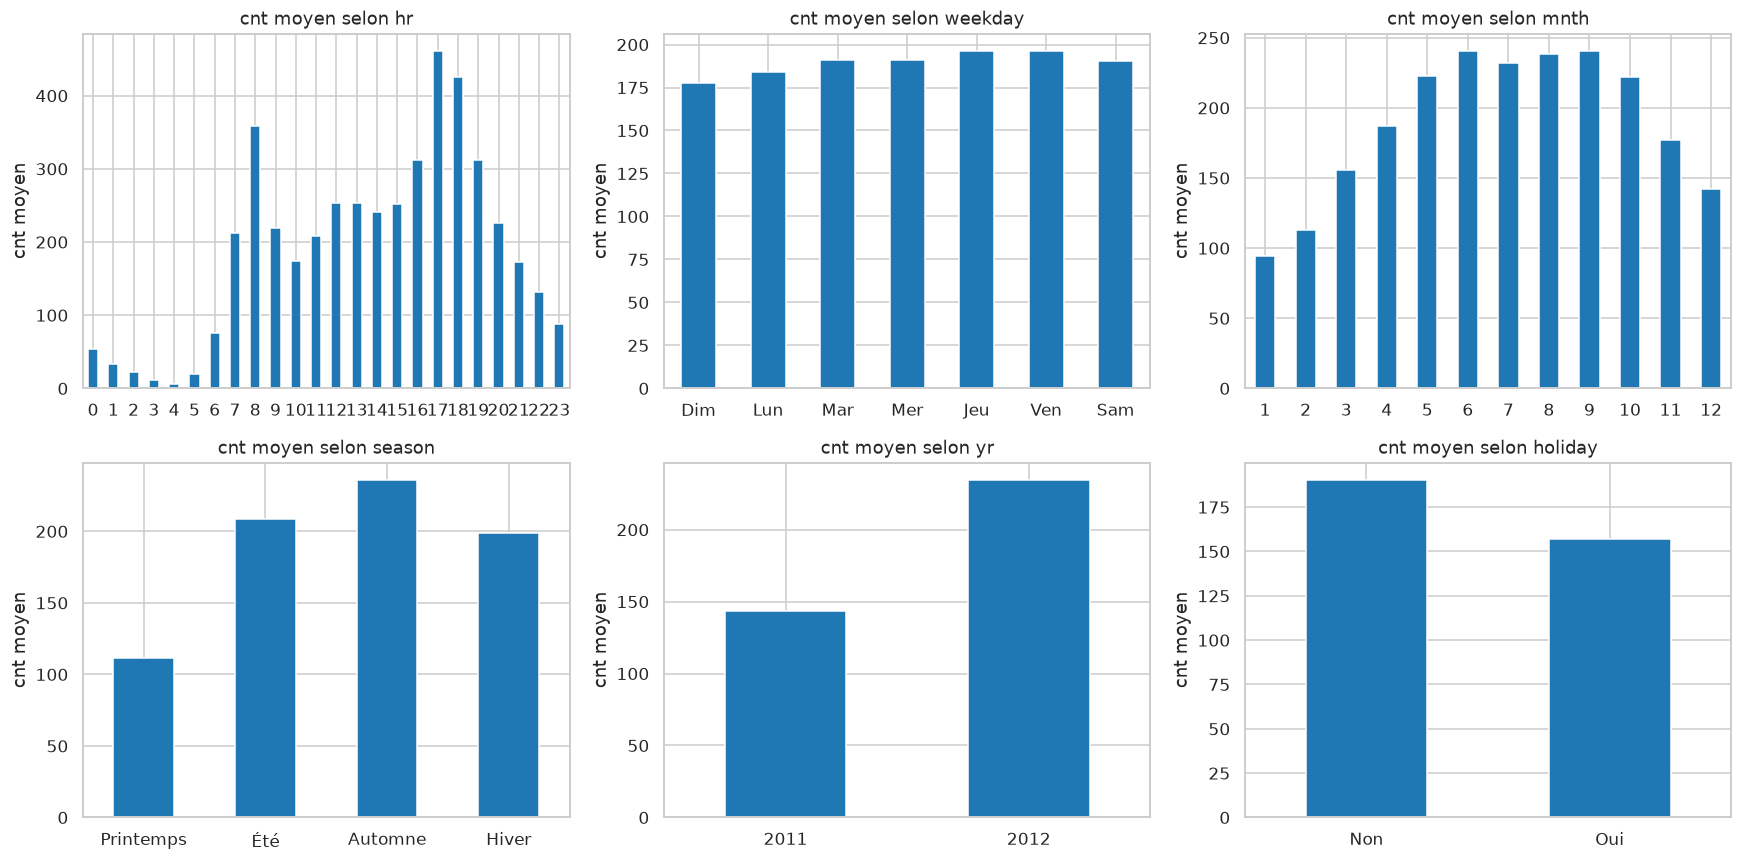

In [46]:
labels = {
    "weekday": {0: "Dim", 1: "Lun", 2: "Mar", 3: "Mer", 4: "Jeu", 5: "Ven", 6: "Sam"},
    "season":  {1: "Printemps", 2: "Été", 3: "Automne", 4: "Hiver"},
    "yr":      {0: "2011", 1: "2012"},
    "holiday": {0: "Non", 1: "Oui"},
}

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), ["hr", "weekday", "mnth", "season", "yr", "holiday"]):
    m = df.groupby(col)["cnt"].mean()
    if col in labels:
        m.index = m.index.map(labels[col])
    m.plot(kind="bar", ax=ax, color="tab:blue", rot=0)
    ax.set(title=f"cnt moyen selon {col}", xlabel="", ylabel="cnt moyen")
plt.tight_layout(); plt.show()

## 5. Jours ouvrés vs week-end (et jours fériés)

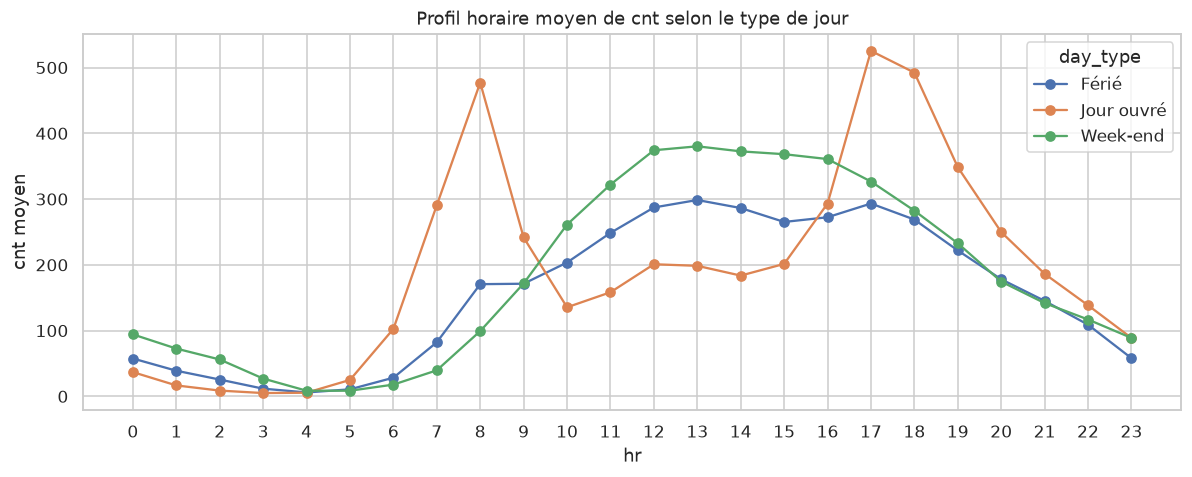

Heure du pic principal :
            hr_du_pic
day_type             
Férié              13
Jour ouvré         17
Week-end           13

Nombre de lignes par type de jour :
day_type
Jour ouvré    11865
Week-end       5014
Férié           500
Name: count, dtype: int64


In [47]:
df["day_type"] = np.select(
    [df["holiday"] == 1, df["workingday"] == 1],
    ["Férié", "Jour ouvré"],
    default="Week-end",
)

profile = df.pivot_table(index="hr", columns="day_type", values="cnt", aggfunc="mean")

fig, ax = plt.subplots(figsize=(11, 4.5))
profile.plot(ax=ax, marker="o")
ax.set(title="Profil horaire moyen de cnt selon le type de jour", xlabel="hr", ylabel="cnt moyen")
ax.set_xticks(range(24))
plt.tight_layout(); plt.show()

print("Heure du pic principal :")
print(profile.idxmax().to_frame("hr_du_pic"))
print("\nNombre de lignes par type de jour :")
print(df["day_type"].value_counts())

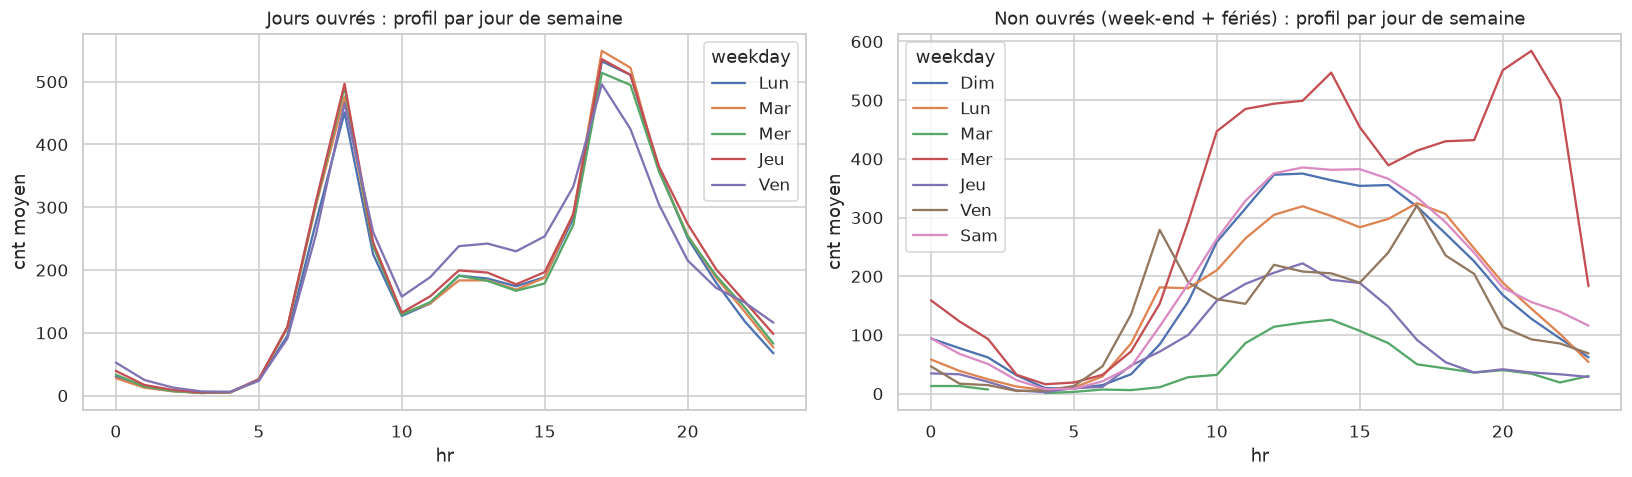

In [48]:
# Jours ouvrés : les deux pics (matin / soir) + évolution selon le jour de la semaine
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

wd = df[df["workingday"] == 1].pivot_table(index="hr", columns="weekday", values="cnt", aggfunc="mean")
wd.rename(columns=labels["weekday"]).plot(ax=axes[0])
axes[0].set(title="Jours ouvrés : profil par jour de semaine", ylabel="cnt moyen")

we = df[df["workingday"] == 0].pivot_table(index="hr", columns="weekday", values="cnt", aggfunc="mean")
we.rename(columns=labels["weekday"]).plot(ax=axes[1])
axes[1].set(title="Non ouvrés (week-end + fériés) : profil par jour de semaine", ylabel="cnt moyen")
plt.tight_layout(); plt.show()

## 6. Impact de la météo

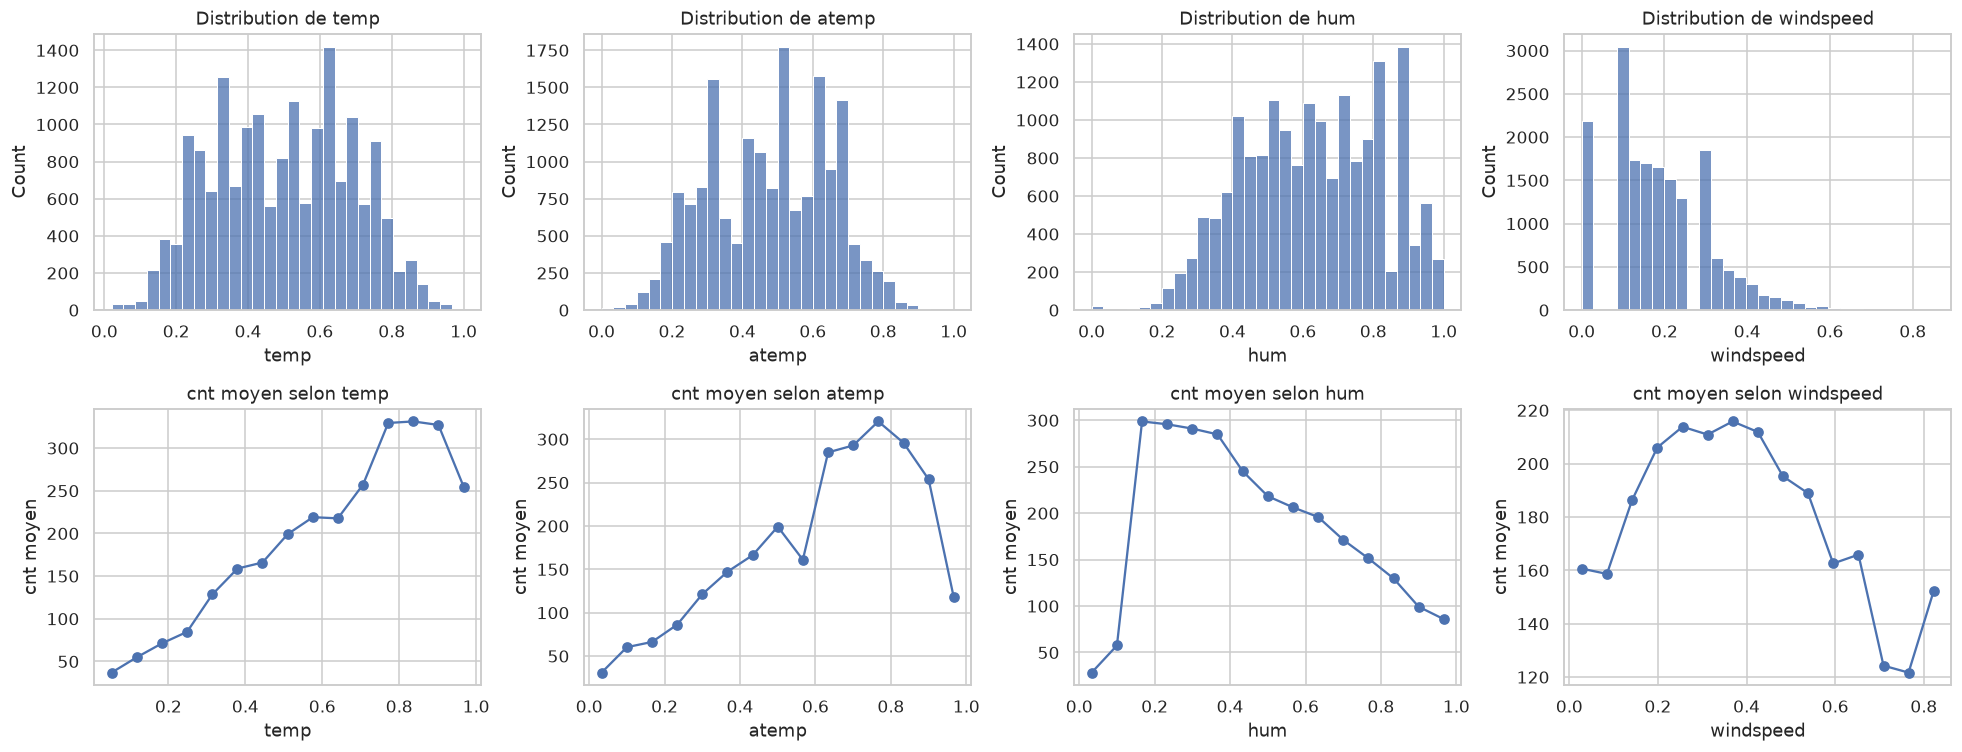

Valeurs suspectes :
  hum == 0       : 22 lignes
  windspeed == 0 : 2180 lignes (12.5%, probablement des valeurs manquantes encodées par 0)


In [49]:
weather_num = ["temp", "atemp", "hum", "windspeed"]

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for j, col in enumerate(weather_num):
    sns.histplot(df[col], bins=30, ax=axes[0, j]); axes[0, j].set_title(f"Distribution de {col}")

    binned = df.groupby(pd.cut(df[col], 15), observed=True)["cnt"].mean()
    x = [iv.mid for iv in binned.index]
    axes[1, j].plot(x, binned.values, marker="o")
    axes[1, j].set(title=f"cnt moyen selon {col}", xlabel=col, ylabel="cnt moyen")
plt.tight_layout(); plt.show()

print("Valeurs suspectes :")
print("  hum == 0       :", int((df["hum"] == 0).sum()), "lignes")
print("  windspeed == 0 :", int((df["windspeed"] == 0).sum()), "lignes",
      f"({(df['windspeed'] == 0).mean():.1%}, probablement des valeurs manquantes encodées par 0)")

            count   mean  median  part_%
weathersit                              
1           11413  204.9   159.0   65.67
2            4544  175.2   133.0   26.15
3            1419  111.6    63.0    8.17
4               3   74.3    36.0    0.02


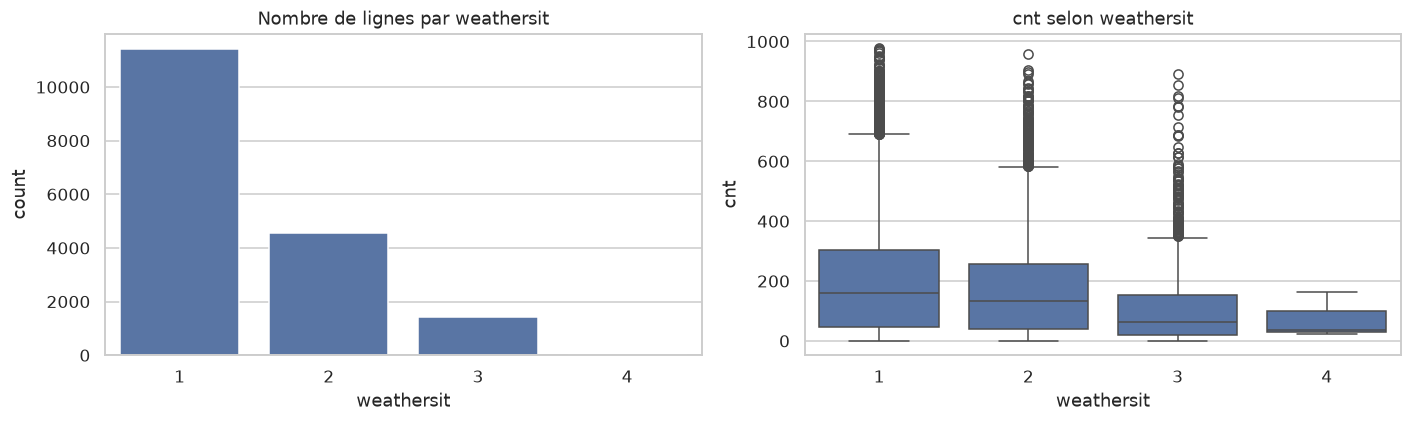

In [50]:
ws = df.groupby("weathersit")["cnt"].agg(["count", "mean", "median"]).round(1)
ws["part_%"] = (100 * ws["count"] / len(df)).round(2)
print(ws)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x="weathersit", ax=axes[0]);     axes[0].set_title("Nombre de lignes par weathersit")
sns.boxplot(data=df, x="weathersit", y="cnt", ax=axes[1]); axes[1].set_title("cnt selon weathersit")
plt.tight_layout(); plt.show()

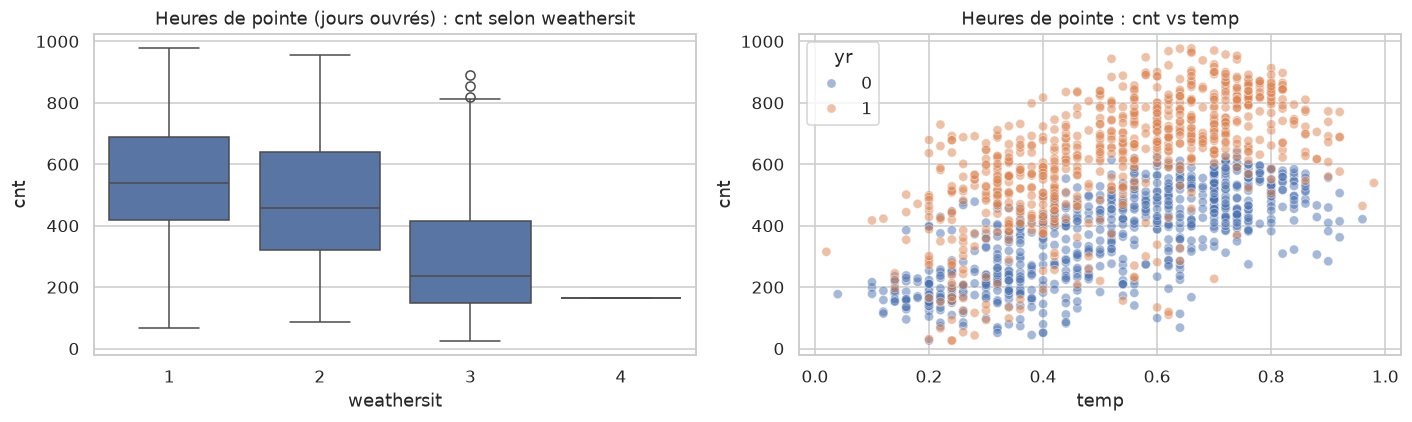

In [51]:
# Effet météo "toutes choses égales par ailleurs" : on regarde en heure de pointe en jour ouvré
rush = df[(df["workingday"] == 1) & (df["hr"].isin([8, 17, 18]))]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=rush, x="weathersit", y="cnt", ax=axes[0]); axes[0].set_title("Heures de pointe (jours ouvrés) : cnt selon weathersit")
sns.scatterplot(data=rush, x="temp", y="cnt", hue="yr", alpha=0.5, ax=axes[1]); axes[1].set_title("Heures de pointe : cnt vs temp")
plt.tight_layout(); plt.show()

## 7. Corrélations et multicolinéarité

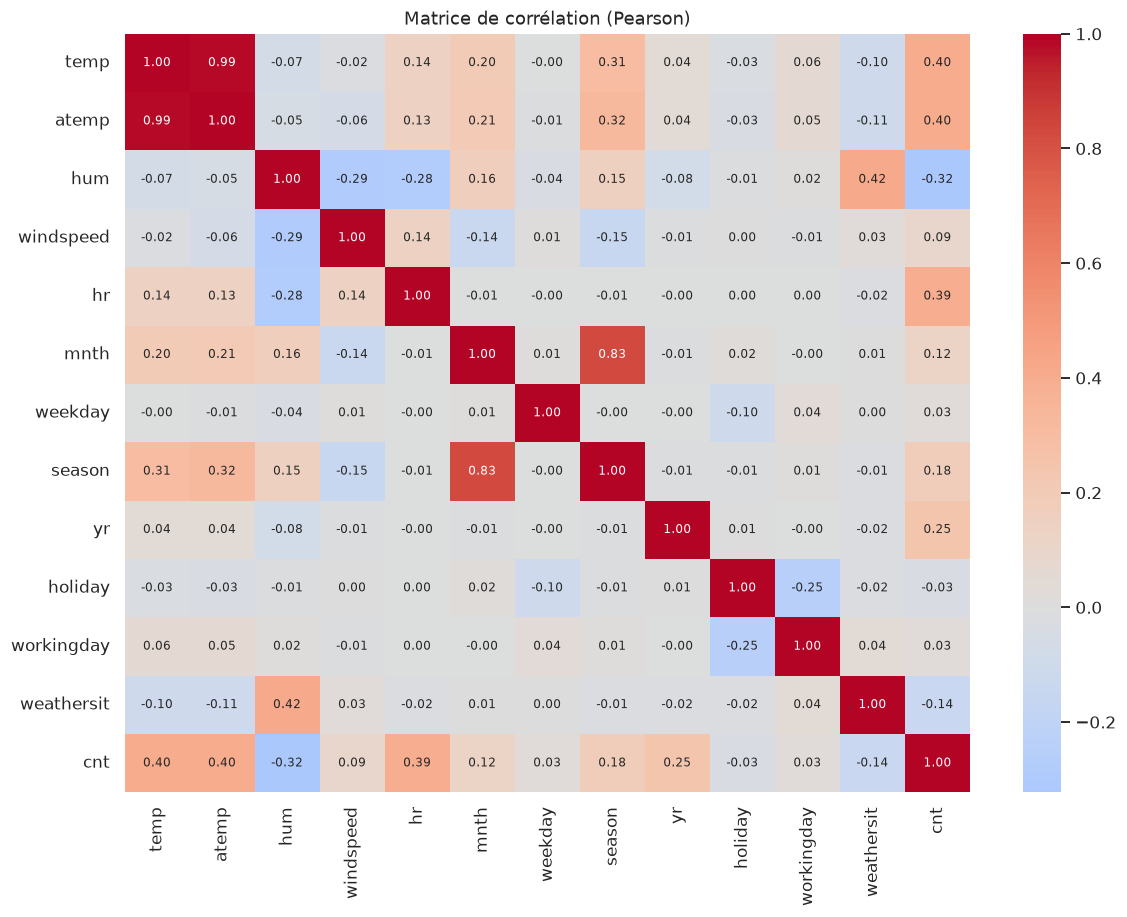

corr(temp, atemp) = 0.988


,pearson,spearman
temp,0.405,0.423
atemp,0.401,0.423
hr,0.394,0.511
hum,-0.323,-0.360
yr,0.250,0.207
season,0.178,0.185
weathersit,-0.142,-0.126
mnth,0.121,0.126
windspeed,0.093,0.127
holiday,-0.031,-0.030


In [52]:
corr_cols = ["temp", "atemp", "hum", "windspeed", "hr", "mnth", "weekday", "season",
             "yr", "holiday", "workingday", "weathersit", "cnt"]

corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, annot_kws={"size": 8})
ax.set_title("Matrice de corrélation (Pearson)")
plt.tight_layout(); plt.show()

print(f"corr(temp, atemp) = {df['temp'].corr(df['atemp']):.3f}")

spearman = df[corr_cols].corr(method="spearman")["cnt"].drop("cnt")
pearson = corr["cnt"].drop("cnt")
pd.DataFrame({"pearson": pearson, "spearman": spearman}).sort_values("pearson", key=abs, ascending=False).round(3)

In [53]:
def vif_table(X):
    """VIF = 1 / (1 - R²) de la régression de chaque variable sur les autres."""
    X = X.astype(float)
    out = {}
    for c in X.columns:
        y = X[c].values
        A = np.column_stack([np.ones(len(X)), X.drop(columns=c).values])
        beta, *_ = np.linalg.lstsq(A, y, rcond=None)
        r2 = 1 - (y - A @ beta).var() / y.var()
        out[c] = 1 / (1 - r2)
    return pd.Series(out).sort_values(ascending=False)

feat = ["temp", "atemp", "hum", "windspeed", "workingday", "weathersit", "yr"]
print("VIF avec temp ET atemp :")
print(vif_table(df[feat]).round(1))

print("\nVIF sans atemp :")
print(vif_table(df[[c for c in feat if c != "atemp"]]).round(1))

VIF avec temp ET atemp :
atemp         43.7
temp          43.6
hum            1.4
weathersit     1.3
windspeed      1.2
yr             1.0
workingday     1.0
dtype: float64

VIF sans atemp :
hum           1.4
weathersit    1.3
windspeed     1.1
temp          1.0
yr            1.0
workingday    1.0
dtype: float64


## 8. `casual` vs `registered` (pour la compréhension uniquement)

Part du total des locations :
casual        0.188
registered    0.812
dtype: float64

Part de casual selon le type de jour :
day_type
Férié         0.285
Jour ouvré    0.132
Week-end      0.319
dtype: float64


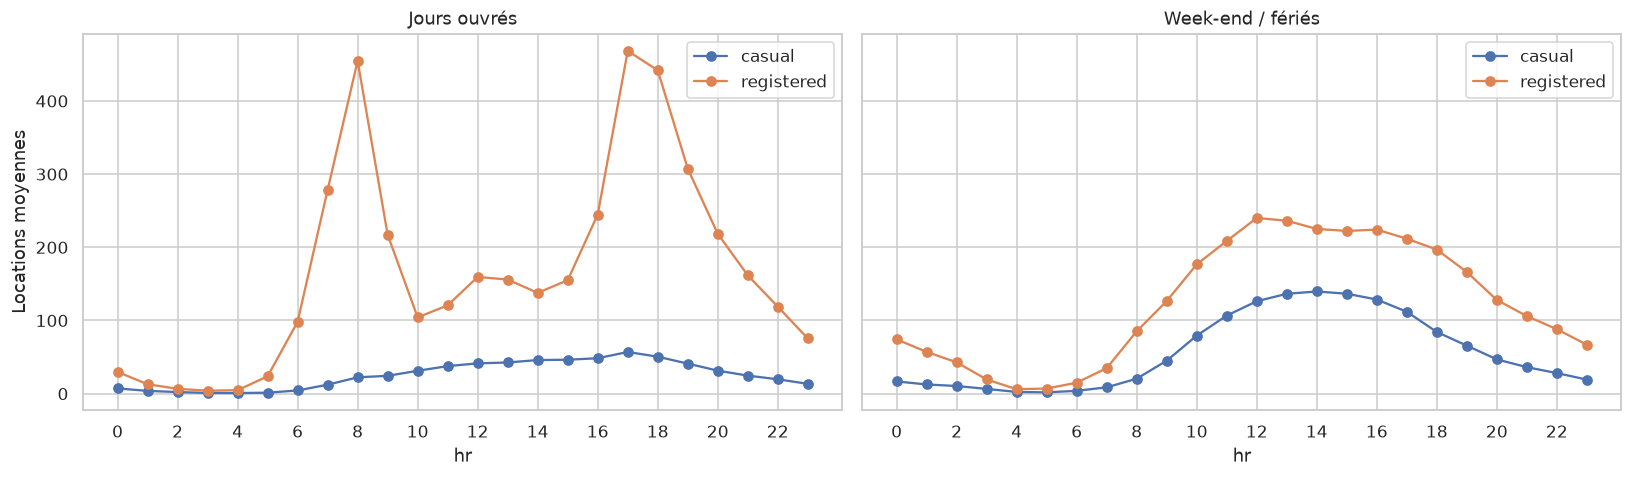

In [54]:
print("Part du total des locations :")
print((df[["casual", "registered"]].sum() / df["cnt"].sum()).round(3))

print("\nPart de casual selon le type de jour :")
print(df.groupby("day_type")[["casual", "registered"]].sum().pipe(lambda t: t["casual"] / (t["casual"] + t["registered"])).round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, (wk, title) in zip(axes, [(1, "Jours ouvrés"), (0, "Week-end / fériés")]):
    p = df[df["workingday"] == wk].groupby("hr")[["casual", "registered"]].mean()
    p.plot(ax=ax, marker="o")
    ax.set(title=title, xlabel="hr", ylabel="Locations moyennes")
    ax.set_xticks(range(0, 24, 2))
plt.tight_layout(); plt.show()

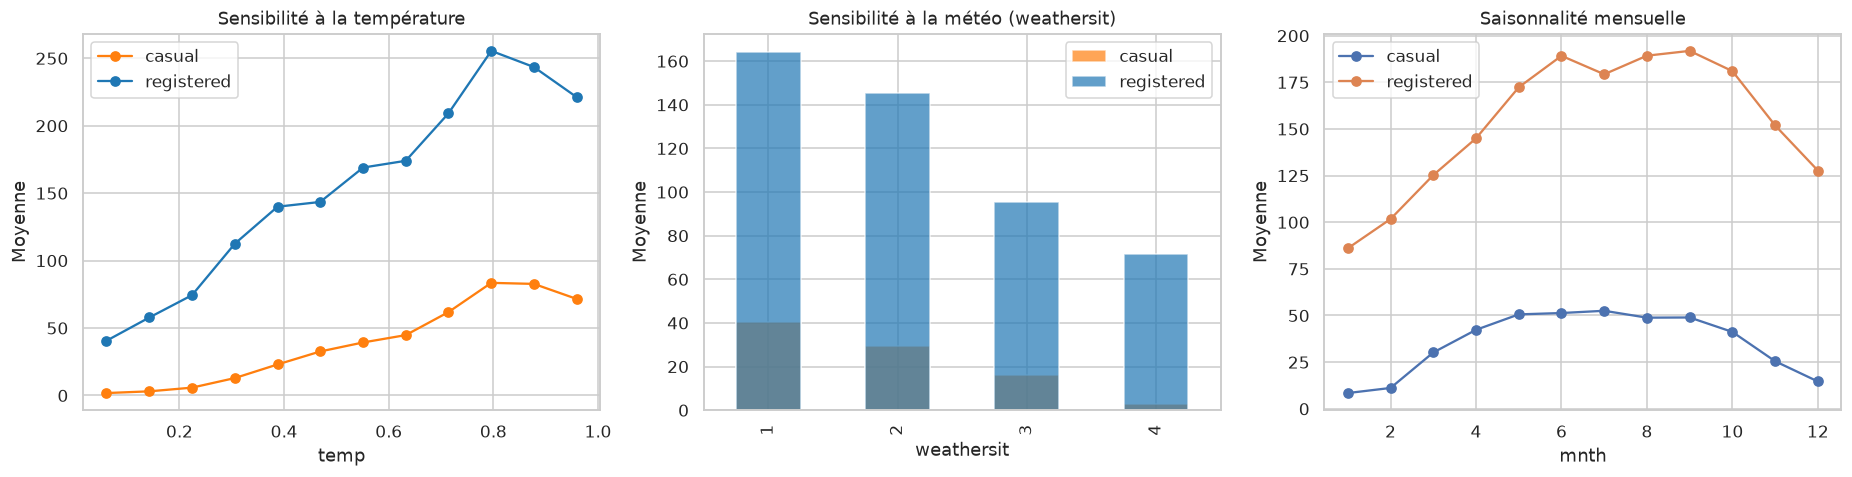

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for col, color in [("casual", "tab:orange"), ("registered", "tab:blue")]:
    b = df.groupby(pd.cut(df["temp"], 12), observed=True)[col].mean()
    axes[0].plot([iv.mid for iv in b.index], b.values, marker="o", label=col, color=color)
axes[0].set(title="Sensibilité à la température", xlabel="temp", ylabel="Moyenne"); axes[0].legend()

for col, color in [("casual", "tab:orange"), ("registered", "tab:blue")]:
    df.groupby("weathersit")[col].mean().plot(kind="bar", ax=axes[1], alpha=0.7, label=col, color=color)
axes[1].set(title="Sensibilité à la météo (weathersit)", ylabel="Moyenne"); axes[1].legend()

df.groupby(["mnth"])[["casual", "registered"]].mean().plot(ax=axes[2], marker="o")
axes[2].set(title="Saisonnalité mensuelle", ylabel="Moyenne")
plt.tight_layout(); plt.show()

## 9. Croissance entre 2011 et 2012 (tendance)

In [56]:
monthly = df.groupby(["yr", "mnth"])["cnt"].sum().unstack("yr")
monthly.columns = ["2011", "2012"]
monthly["croissance_%"] = ((monthly["2012"] / monthly["2011"] - 1) * 100).round(1)
print(monthly)

tot = df.groupby("yr")["cnt"].sum()
print(f"\nTotal 2011 : {tot[0]:,}   Total 2012 : {tot[1]:,}   Croissance : {tot[1] / tot[0] - 1:+.1%}")

        2011    2012  croissance_%
mnth                              
1      38189   96744         153.3
2      48215  103137         113.9
3      64045  164875         157.4
4      94870  174224          83.6
5     135821  195865          44.2
6     143512  202830          41.3
7     141341  203607          44.1
8     136691  214503          56.9
9     127418  218573          71.5
10    123511  198841          61.0
11    102167  152664          49.4
12     87323  123713          41.7

Total 2011 : 1,243,103   Total 2012 : 2,049,576   Croissance : +64.9%


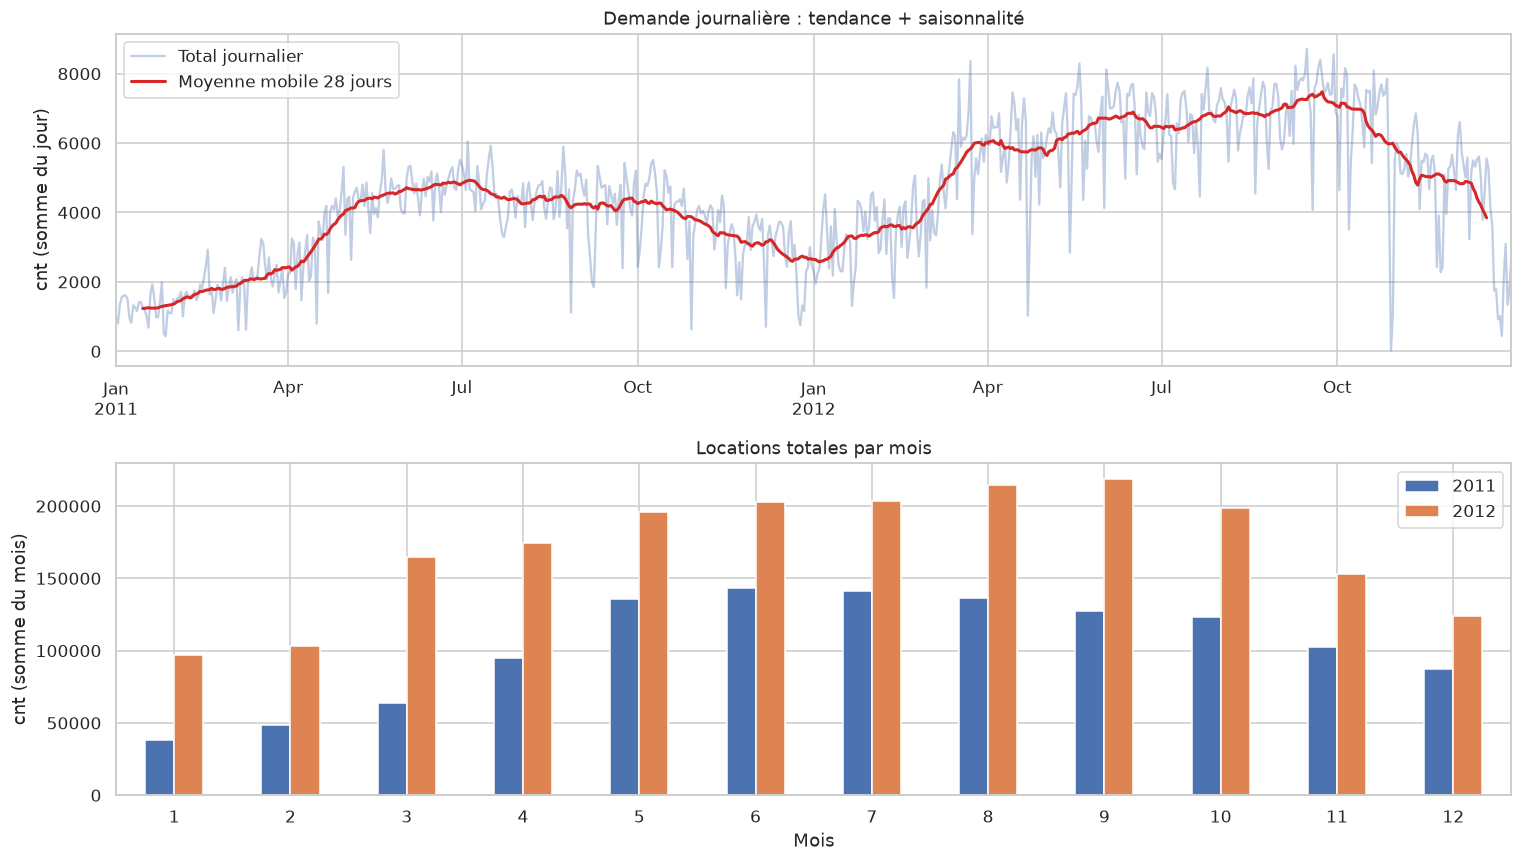

In [57]:
daily = df.groupby("dteday")["cnt"].sum()

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
daily.plot(ax=axes[0], alpha=0.35, label="Total journalier")
daily.rolling(28, center=True).mean().plot(ax=axes[0], color="tab:red", linewidth=2, label="Moyenne mobile 28 jours")
axes[0].set(title="Demande journalière : tendance + saisonnalité", ylabel="cnt (somme du jour)", xlabel="")
axes[0].legend()

monthly[["2011", "2012"]].plot(kind="bar", ax=axes[1], rot=0)
axes[1].set(title="Locations totales par mois", xlabel="Mois", ylabel="cnt (somme du mois)")
plt.tight_layout(); plt.show()

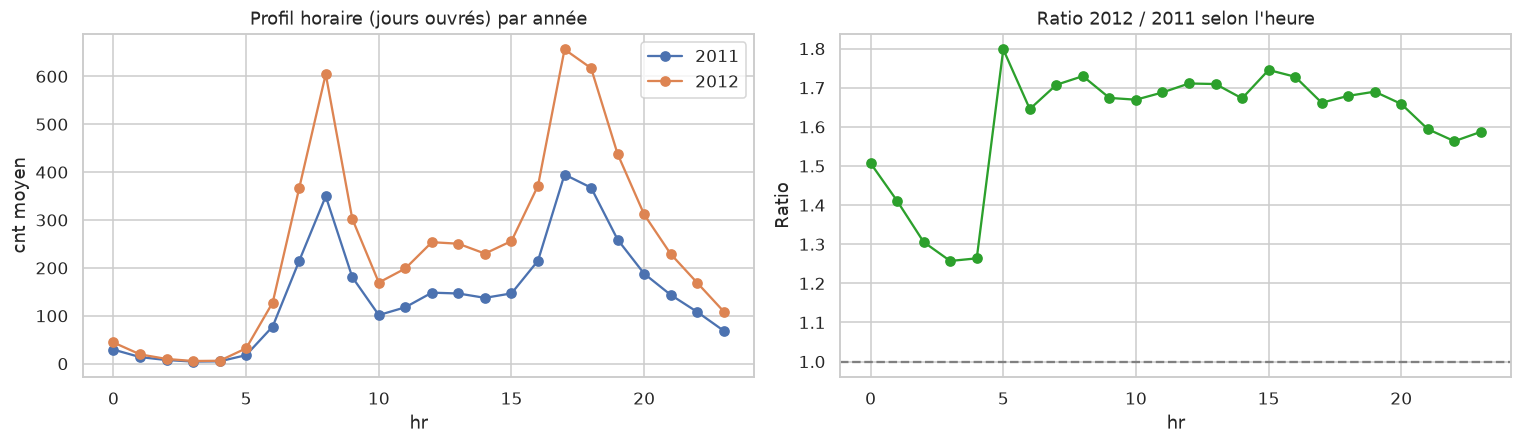

In [58]:
# Le profil horaire change-t-il d'une année à l'autre, ou seulement le niveau ?
prof_yr = df[df["workingday"] == 1].pivot_table(index="hr", columns="yr", values="cnt", aggfunc="mean")
prof_yr.columns = ["2011", "2012"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
prof_yr.plot(ax=axes[0], marker="o"); axes[0].set(title="Profil horaire (jours ouvrés) par année", ylabel="cnt moyen")
(prof_yr["2012"] / prof_yr["2011"]).plot(ax=axes[1], marker="o", color="tab:green")
axes[1].axhline(1, color="gray", linestyle="--")
axes[1].set(title="Ratio 2012 / 2011 selon l'heure", ylabel="Ratio")
plt.tight_layout(); plt.show()

## Synthèse de l'EDA (à compléter après exécution)

| Thème | Constat | Conséquence pour la modélisation |
|---|---|---|
| Qualité des données | | |
| Continuité temporelle | | |
| Distribution de `cnt` | | |
| Effet de l'heure / type de jour | | |
| Météo | | |
| Multicolinéarité | | |
| Tendance 2011 → 2012 | | |